# Investigation of Hospital Length of Stay
- Author: Sydney Sailors
- Date: 2026-11-09

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned MEPS dataset
df = pd.read_csv("../data/processed/meps_los_clean.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1912, 20)


,DUPERSID,NUMNIGHX,EMERROOM,RSNINHOS,ANYOPER,IPXP24X,IPTC24X,AGE24X,SEX,RACETHX,RTHLTH53,MNHLTH53,INSCOV24,REGION24,PERWT24F,DIABDX_M18,HIBPDX,CHDDX,STRKDX,ASTHDX
0,2810003101,1,2,2.0,2.0,899.43,5581.00,67.0,2,2,3.0,4.0,2,4.0,16532.179401,2.0,2.0,2.0,2.0,2.0
1,2810032102,1,2,1.0,1.0,10429.73,59673.59,68.0,1,2,2.0,2.0,1,2.0,6895.352058,2.0,1.0,2.0,2.0,2.0
2,2810046101,7,1,2.0,2.0,12155.57,33308.93,76.0,2,2,3.0,2.0,2,2.0,10604.873319,2.0,1.0,2.0,1.0,2.0
3,2810049101,1,2,1.0,1.0,15841.74,56681.50,55.0,1,2,2.0,2.0,1,3.0,19142.735735,1.0,1.0,2.0,2.0,1.0
4,2810061101,19,2,2.0,2.0,13595.22,60421.53,70.0,1,3,5.0,4.0,2,1.0,9953.079010,2.0,1.0,2.0,2.0,1.0


## Statistics and Visualizations

In [2]:
# Summary statistics for length of stay
print(df["NUMNIGHX"].describe())

# Number of missing values
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

count    1912.000000
mean        4.880753
std         8.009832
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       155.000000
Name: NUMNIGHX, dtype: float64

Missing values:
MNHLTH53      140
RTHLTH53      139
CHDDX         126
HIBPDX        125
STRKDX        124
REGION24       92
AGE24X         92
RSNINHOS       23
ANYOPER        19
DIABDX_M18     15
ASTHDX         15
DUPERSID        0
EMERROOM        0
NUMNIGHX        0
IPXP24X         0
IPTC24X         0
SEX             0
RACETHX         0
PERWT24F        0
INSCOV24        0
dtype: int64


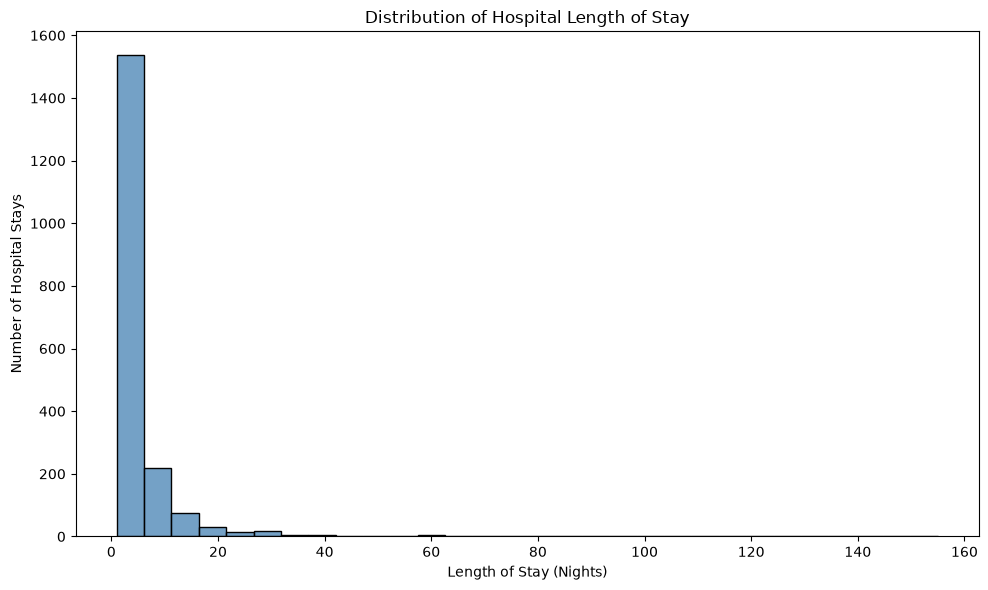

In [3]:
# Histogram for length of stay
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="NUMNIGHX",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Hospital Length of Stay")
plt.xlabel("Length of Stay (Nights)")
plt.ylabel("Number of Hospital Stays")

plt.tight_layout()
plt.show()

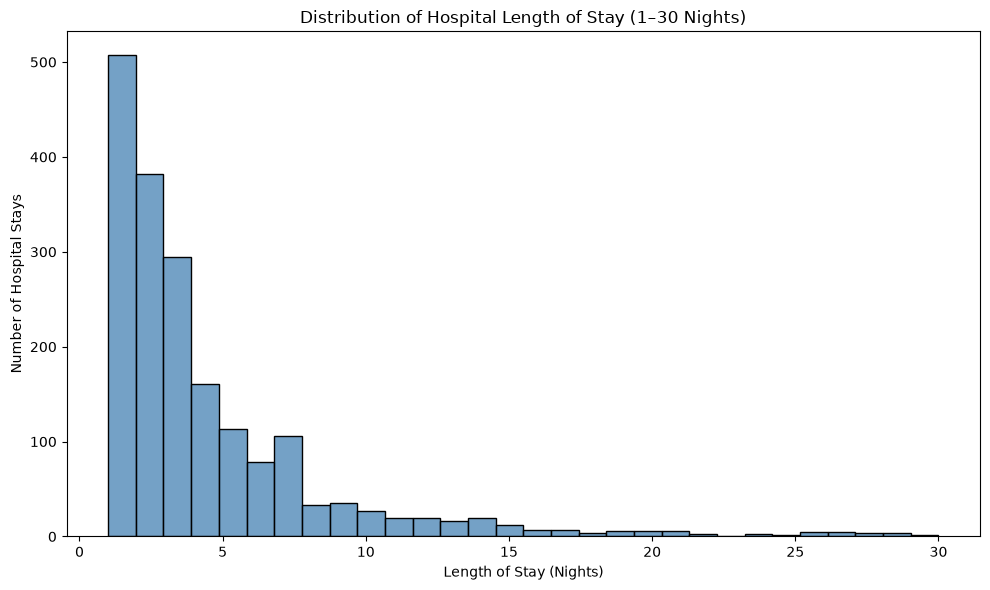

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df[df["NUMNIGHX"] <= 30],
    x="NUMNIGHX",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Hospital Length of Stay (1–30 Nights)")
plt.xlabel("Length of Stay (Nights)")
plt.ylabel("Number of Hospital Stays")

plt.tight_layout()
plt.show()

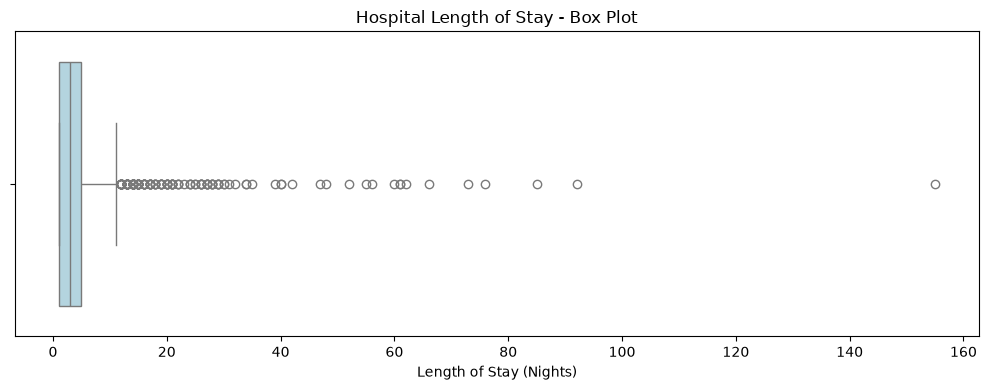

In [4]:
# Box plot for length of stay
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="NUMNIGHX",
    color="lightblue"
)

plt.title("Hospital Length of Stay - Box Plot")
plt.xlabel("Length of Stay (Nights)")

plt.tight_layout()
plt.show()

In [5]:
Q1 = df["NUMNIGHX"].quantile(0.25)
Q3 = df["NUMNIGHX"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = df[df["NUMNIGHX"] > upper_bound]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier threshold:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:",
      round(len(outliers) / len(df) * 100, 2), "%")

Q1: 1.0
Q3: 5.0
IQR: 4.0
Upper outlier threshold: 11.0
Number of potential outliers: 156
Percentage of potential outliers: 8.16 %


Descriptive statistics, histograms, and box plots were utilized to examine the distribution of hospital length of stay. Out of the 1,912 inpatient stays, the minimum length of stay was 1 night and the maximum was 155 nights. On average, patients spent approximately 4.88 nights in the hospital while the median length of stay was 3 nights. The distribution was positively skewed, or right skewed, which indicates that most hospitalizations were relatively short. 

The interquartile range (IQR) method showed that hospitalizations exceeding 11 nights were considered potential outliers. There's a total of 156 records (8.16%) that exceed this threshold, with the longest length of stay being 155 nights. Since extended hospital stays may repreesnt legitimate cases relevant to the research question, those outliers were retained. 

## Age vs Length of Stay and Visuals

In [8]:
age_bins = [0, 17, 34, 49, 64, 120]
age_labels = ["0–17", "18–34", "35–49", "50–64", "65+"]

df["Age_Group"] = pd.cut(
    df["AGE24X"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_summary = (
    df.groupby("Age_Group", observed=True)["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(age_summary)

           count  mean  median
Age_Group                     
0–17         101  3.61     2.0
18–34        194  3.81     2.0
35–49        198  5.04     3.0
50–64        384  4.55     3.0
65+          943  5.11     3.0


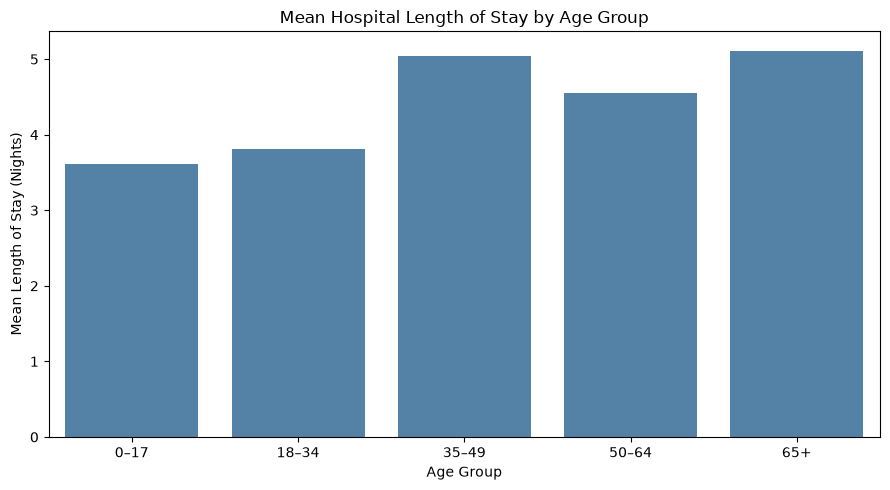

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Age_Group",
    y="NUMNIGHX",
    estimator="mean",
    errorbar=None,
    color="steelblue"
)

plt.title("Mean Hospital Length of Stay by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Mean Length of Stay (Nights)")

plt.tight_layout()
plt.show()

## Sex vs Length of Stay and Visuals

In [11]:
sex_summary = (
    df.groupby("SEX")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

sex_summary.index = sex_summary.index.map({
    1: "Male",
    2: "Female"
})

print(sex_summary)

        count  mean  median
SEX                        
Male      796  5.23     3.0
Female   1116  4.63     3.0


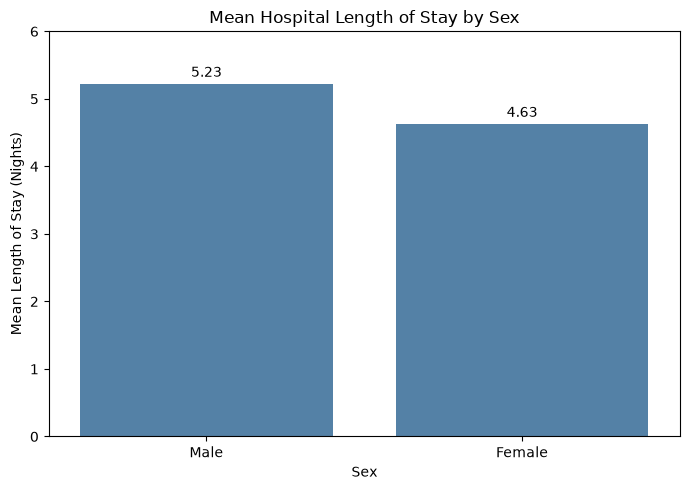

In [12]:
sex_plot = (
    df.groupby("SEX")["NUMNIGHX"]
    .mean()
    .rename(index={1: "Male", 2: "Female"})
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=sex_plot.index,
    y=sex_plot.values,
    color="steelblue"
)

for i, value in enumerate(sex_plot.values):
    ax.text(i, value + 0.1, f"{value:.2f}", ha="center")

plt.title("Mean Hospital Length of Stay by Sex")
plt.xlabel("Sex")
plt.ylabel("Mean Length of Stay (Nights)")
plt.ylim(0, 6)

plt.tight_layout()
plt.show()

## Emergency Room vs Length of Stay and Visuals

In [13]:
er_summary = (
    df.groupby("EMERROOM")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

er_summary.index = er_summary.index.map({
    1: "Yes",
    2: "No"
})

print(er_summary)

          count  mean  median
EMERROOM                     
Yes        1020  4.81     3.0
No          892  4.96     2.0


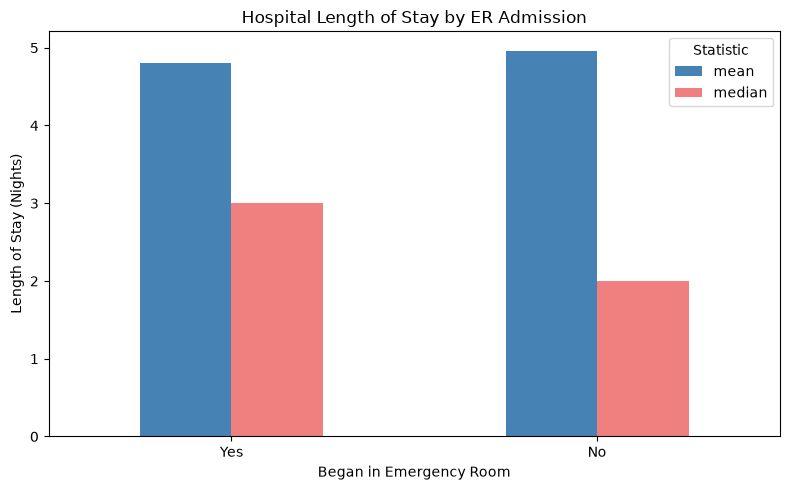

In [14]:
er_plot = (
    df.groupby("EMERROOM")["NUMNIGHX"]
    .agg(["mean", "median"])
    .rename(index={1: "Yes", 2: "No"})
)

er_plot.index.name = "Began in ER"

ax = er_plot.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "lightcoral"],
    rot=0
)

plt.title("Hospital Length of Stay by ER Admission")
plt.xlabel("Began in Emergency Room")
plt.ylabel("Length of Stay (Nights)")
plt.legend(title="Statistic")

plt.tight_layout()
plt.show()